# PASSAGE Display
Browse local samples under `outputs/dataset` by resolution and split, then render tensors, paths, and optional PNGs. Set `RESOLUTION`, `SPLIT`, and `SAMPLE_INDEX` (or leave `None` to auto-pick the first available).

In [ ]:
from pathlib import Path
from typing import Iterable
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml

# Allow importing project modules
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC_ROOT = ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

# Import project visualization after adjusting sys.path
try:
    from passage.visualization import tensor_to_image  # noqa: E402
except Exception:  # pragma: no cover
    tensor_to_image = None

DATASET_ROOT = ROOT / "outputs" / "dataset"


def parse_path_txt(txt_path: Path) -> list[tuple[int, int]]:
    """Parse a path .txt file written as: "0 x0 y0 x1 y1 ..." and return [(i, j), ...]."""
    txt = txt_path.read_text().strip()
    if not txt:
        return []
    parts = txt.split()
    if len(parts) < 3:
        return []
    coords = list(map(int, parts[1:]))
    return [(coords[i + 1], coords[i]) for i in range(0, len(coords) - 1, 2)]


def paths_from_metadata(meta: dict, key: str) -> list[tuple[int, int]]:
    node = (meta.get("paths") or {}).get(key, {})
    pixels = node.get("pixels") or []
    coords: list[tuple[int, int]] = []
    for p in pixels:
        if isinstance(p, dict) and "i" in p and "j" in p:
            coords.append((int(p["i"]), int(p["j"])))
    return coords


def to_array(path_list: Iterable[Iterable[int]] | None) -> np.ndarray | None:
    if not path_list:
        return None
    arr = np.asarray(list(path_list), dtype=int)
    if arr.ndim == 1:
        arr = arr.reshape(-1, 2)
    return arr


def find_sample_paths(resolution: int, split: str, sample_index: int | None):
    base = DATASET_ROOT / str(resolution) / split
    meta_root = base / "metadata"
    pattern = f"{sample_index:010d}.yaml" if sample_index is not None else "*.yaml"
    matches = sorted(meta_root.rglob(pattern))
    if not matches:
        return None
    meta_path = matches[0]
    stem = meta_path.stem
    lat_dir = meta_path.parent.parent.name
    lon_dir = meta_path.parent.name
    return {
        "metadata_path": meta_path,
        "tensor_path": base / "tensors" / lat_dir / lon_dir / f"{stem}.npy",
        "image_path": base / "images" / lat_dir / lon_dir / f"{stem}.png",
        "path_free_txt": base / "paths" / "free" / lat_dir / lon_dir / f"{stem}.txt",
        "path_obstacles_txt": base / "paths" / "obstacles" / lat_dir / lon_dir / f"{stem}.txt",
    }


def summarize(meta: dict) -> str:
    res = meta.get("resolution")
    split = meta.get("split")
    target_elev = meta.get("target_elevation")
    free_len = (meta.get("paths") or {}).get("without_obstacles", {}).get("length")
    obs_len = (meta.get("paths") or {}).get("with_obstacles", {}).get("length")
    parts = [f"resolution={res}" if res is not None else "", f"split={split}" if split else ""]
    desc = " ".join([p for p in parts if p])
    if target_elev is not None:
        desc += f", target_elevation={target_elev:.1f}"
    if free_len is not None or obs_len is not None:
        desc += f" | path len free={free_len}, obstacles={obs_len}"
    return desc.strip()

In [37]:
# Configuration
RESOLUTION = 2048
SPLIT = "train"  # train | validation | calibration | test
SAMPLE_INDEX = 6  # set to an int to target a specific sample, or None to auto-pick the first

paths = find_sample_paths(RESOLUTION, SPLIT, SAMPLE_INDEX)
tensor = None
image = None
metadata = {}
path_free = None
path_obstacles = None

if not paths:
    print(f"No sample found for resolution={RESOLUTION}, split={SPLIT}, index={SAMPLE_INDEX}")
else:
    metadata = yaml.safe_load(paths["metadata_path"].read_text()) or {}
    print(f"Using metadata: {paths['metadata_path']}")
    tensor_path = paths["tensor_path"]
    if tensor_path.exists():
        tensor = np.load(tensor_path)
    image_path = paths["image_path"]
    if image_path.exists():
        image = plt.imread(image_path)
    path_free = paths_from_metadata(metadata, "without_obstacles")
    path_obstacles = paths_from_metadata(metadata, "with_obstacles")
    if not path_free and paths["path_free_txt"].exists():
        path_free = parse_path_txt(paths["path_free_txt"])
    if not path_obstacles and paths["path_obstacles_txt"].exists():
        path_obstacles = parse_path_txt(paths["path_obstacles_txt"])
    path_free = to_array(path_free)
    path_obstacles = to_array(path_obstacles)
    print(
        f"tensor shape={getattr(tensor, 'shape', None)}, image={'yes' if image is not None else 'no'}, "
        f"path_free={path_free.shape[0] if path_free is not None else 0}, "
        f"path_obstacles={path_obstacles.shape[0] if path_obstacles is not None else 0}",
    )
    if metadata:
        print(summarize(metadata))

Using metadata: /home/t0300081/projects/PASSAGE/passage/outputs/dataset/2048/train/metadata/N028/E084/0000000006.yaml
tensor shape=(2048, 2048, 3), image=yes, path_free=958, path_obstacles=929
resolution=2048 split=train, target_elevation=7786.0 | path len free=958, obstacles=929


2026-01-23 14:35:11.558 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.1070, max=0.9220
2026-01-23 14:35:11.576 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-23 14:35:11.720 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d


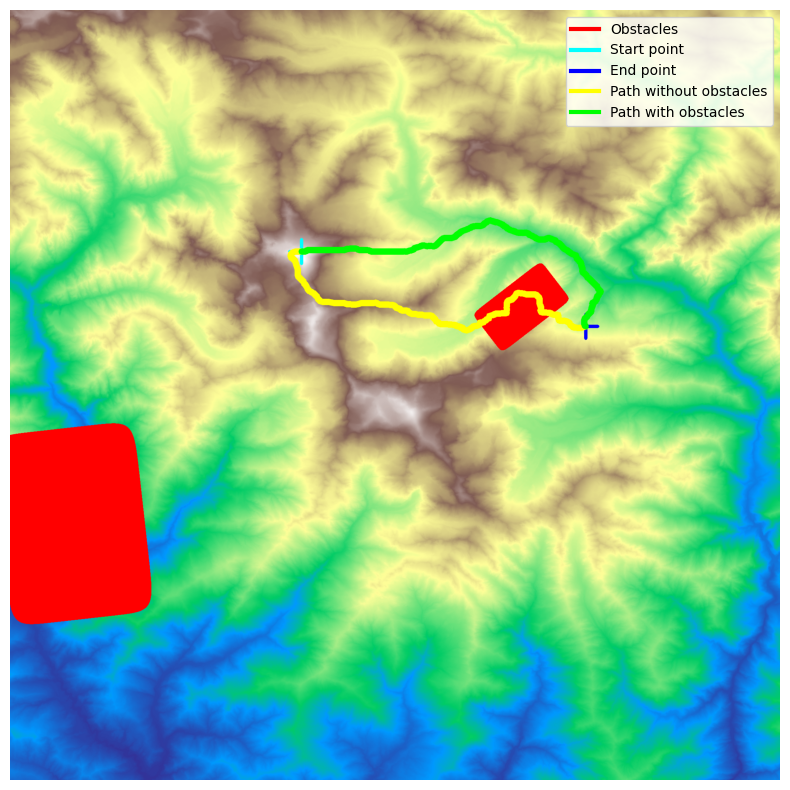

In [39]:
if tensor is not None:
    from matplotlib.lines import Line2D

    path_free_list = None if path_free is None else [tuple(p) for p in path_free.tolist()]
    path_obstacles_list = None if path_obstacles is None else [tuple(p) for p in path_obstacles.tolist()]
    vis_bgr = tensor_to_image(tensor, path_pixels=path_free_list, alt_path_pixels=path_obstacles_list)
    vis_rgb = vis_bgr[:, :, ::-1]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(vis_rgb)
    # ax.set_title("PASSAGE sample visualizatio")
    ax.axis("off")

    legend_handles = [
        Line2D([0], [0], color="#ff0000", lw=3, label="Obstacles"),
        Line2D([0], [0], color="#00ffff", lw=3, label="Start point"),
        Line2D([0], [0], color="#0000ff", lw=3, label="End point"),
        Line2D([0], [0], color="#ffff00", lw=3, label="Path without obstacles"),
        Line2D([0], [0], color="#00ff00", lw=3, label="Path with obstacles"),
    ]
    ax.legend(handles=legend_handles, loc="upper right", frameon=True)

    plt.tight_layout()
    plt.show()
else:
    print("Tensor missing; check the configuration above.")